## load CIFAR10 data from kaggle

In [ ]:
# load CIFAR10 data from kaggle
import os
from google.colab import files

# 1. Upload your kaggle.json file
uploaded = files.upload()

# 2. Create the ~/.kaggle directory if it doesn't exist
os.makedirs('/root/.kaggle', exist_ok=True)

# 3. Move the uploaded kaggle.json file to ~/.kaggle/
!mv kaggle.json /root/.kaggle/

# 4. Set appropriate file permissions (read/write for owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API key configured successfully!")

Saving kaggle_api.json to kaggle_api.json
mv: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API key configured successfully!


In [ ]:
# Install Kaggle library if not already installed
!pip install -q kaggle

# Download the dataset (replace with your dataset's API command)
!kaggle datasets download -d fedesoriano/cifar10-python-in-csv

# Unzip the downloaded dataset into a specific directory
import zipfile

dataset_zip = "cifar10-python-in-csv.zip"  # Replace with the actual zip filename downloaded

with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
    zip_ref.extractall('dataset_folder')

print("Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/fedesoriano/cifar10-python-in-csv
License(s): copyright-authors
100% 209M/209M [00:11<00:00, 18.7MB/s]

Dataset downloaded and extracted!


import necessary libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms

check the cuda device

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available()  else "cpu")
device

device(type='cuda')

In [ ]:
train = pd.read_csv('dataset_folder/train.csv')
test = pd.read_csv('dataset_folder/test.csv')

In [ ]:
train.shape, test.shape

((50000, 3073), (10000, 3072))

In [ ]:
x_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]
x_test = test.copy()

In [ ]:
x_train.shape, y_train.shape, x_test.shape

((50000, 3072), (50000,), (10000, 3072))

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=10000, random_state = 3)

In [ ]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((40000, 3072), (10000, 3072), (40000,), (10000,))

In [ ]:
class_map = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

## Transfer learning with freezed convolution layer and no data augmentation

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models import resnet18, ResNet18_Weights

# model = resnet50(weights=ResNet50_Weights.DEFAULT)
model = resnet18(weights=ResNet18_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 200MB/s]


- ResNet-50 is a pre-trained model that is trained on ImageNet, which has 1,000 output classes.

- CIFAR-10 has only 10 classes, so we replace the final layer and freeze the convolution layers

Freeze all the parameters and then change the classifier layer

In [ ]:
# freeze all parameters
for param in model.parameters():
    param.requires_grad = False

#change the output classifier layer
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam( model.fc.parameters(), lr=0.001 )  # only update the classifier layer weights

- This ResNet50 was trained on an image size of 224x224 but we have an image of size 32x32, so we need to set a transformer that can resize our image.

In [ ]:
from torchvision.transforms import transforms

tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
]
)

In [ ]:
from PIL import Image
class d_set(Dataset):

  def __init__(self, x: np.ndarray, y: np.ndarray, transform = None):

    self.x = x
    self.y = y
    self.transform = transform

  def __getitem__(self, idx):
    image = self.x[idx].reshape(3, 32, 32).transpose(1, 2, 0).astype(np.uint8)
    image = Image.fromarray(image)  #convert to PIL image for transformation

    if self.transform:
        image = self.transform(image)

    label = torch.tensor(self.y[idx], dtype=torch.long)

    return image, label

  def __len__(self):
    return self.x.shape[0]

Create the dataset and dataloader

In [ ]:
train_set = d_set(x_train.values, y_train.values, tf)
val_set = d_set(x_val.values, y_val.values, tf)

#iterable dataloaders
train_loader = DataLoader(train_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch
val_loader = DataLoader(val_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch

len(train_set), len(val_set)

(40000, 10000)

Visualize the transformed images

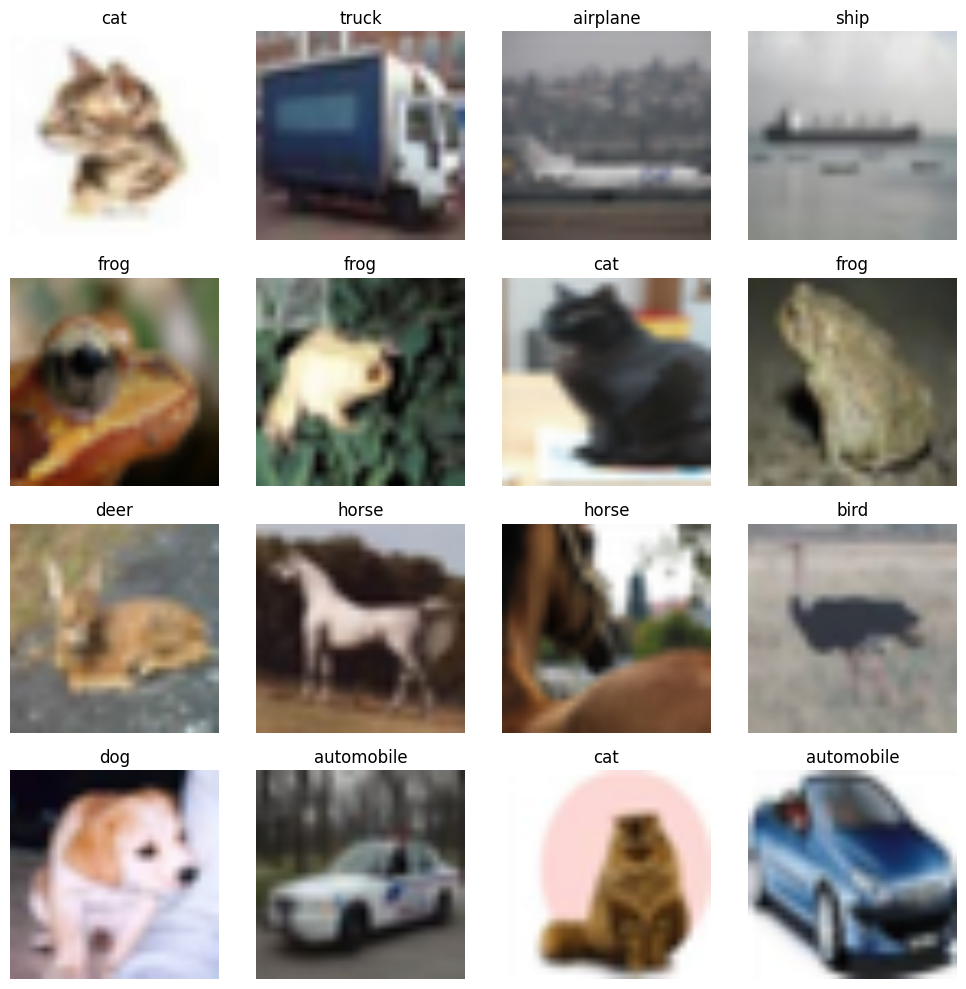

In [ ]:
#visualize the images

# Reverse normalization for better visualization
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

plt.figure(figsize = (10, 10))
for i in range(16):
  plt.subplot(4,4, i+1)
  plt.imshow(inv_normalize(train_set[i][0]).permute(1,2,0))
  plt.title(f"{class_map[train_set[i][1].item()]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

# Train

- ResNet-50 was taking a long time so we decided to use ResNet-18, which is a smaller version, and it would be faster to train

In [ ]:
# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

epochs = 30

for e in range(epochs):
  # ------------------ TRAINING PHASE ------------------
  model.eval() # Keep the frozen layer in evaluation mode including its BatchNorm running statistics.
  model.fc.train()
  train_loss = 0.0

  for batch_x, batch_y in train_loader:
      # Move data to GPU
      batch_x, batch_y = batch_x.to(device), batch_y.to(device)

      # Forward pass
      y_pred = model(batch_x)
      loss = criterion(y_pred, batch_y)

      # Backward propagation
      optimizer.zero_grad()
      loss.backward()

      # Update weights
      optimizer.step()

      train_loss += loss.item()

  avg_train_loss = train_loss / len(train_loader)

  # ------------------ VALIDATION PHASE ------------------
  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = criterion(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # ------------------ EARLY STOPPING LOGIC ------------------
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/30 | Train Loss: 0.6912 | Val Loss: 0.4484
--> Val loss improved! Saving best weights.
Epoch 02/30 | Train Loss: 0.4159 | Val Loss: 0.4005
--> Val loss improved! Saving best weights.
Epoch 03/30 | Train Loss: 0.3771 | Val Loss: 0.3766
--> Val loss improved! Saving best weights.
Epoch 04/30 | Train Loss: 0.3595 | Val Loss: 0.3650
--> Val loss improved! Saving best weights.
Epoch 05/30 | Train Loss: 0.3490 | Val Loss: 0.3557
--> Val loss improved! Saving best weights.
Epoch 06/30 | Train Loss: 0.3381 | Val Loss: 0.3534
--> Val loss improved! Saving best weights.
Epoch 07/30 | Train Loss: 0.3333 | Val Loss: 0.3631
--> No improvement in val loss (1/5)
Epoch 08/30 | Train Loss: 0.3264 | Val Loss: 0.3613
--> No improvement in val loss (2/5)
Epoch 09/30 | Train Loss: 0.3228 | Val Loss: 0.3516
--> Val loss improved! Saving best weights.
Epoch 10/30 | Train Loss: 0.3192 | Val Loss: 0.3536
--> No improvement in val loss (1/5)
Epoch 11/30 | Train Loss: 0.3158 | Val Loss: 0.3474
--> Val l

In [ ]:
# Function to evaluate model accuracy
def eval_model(model, loader, return_labels = False):
  model.eval()
  with torch.no_grad():
    total = 0
    correct = 0
    preds = []
    true_label = []

    for batch_x, batch_y in loader:

      batch_x, batch_y = batch_x.to(device), batch_y.to(device)
      true_label.extend(batch_y.tolist())

      y_pred = model(batch_x)
      predictions = y_pred.max(axis = 1)[1]
      preds.extend(predictions)

      total = total + batch_x.shape[0]
      correct += (predictions == batch_y).sum().item()

  accuracy = correct / total

  if return_labels:
    return accuracy, true_label, preds

  return accuracy

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.90255
validation accuracy -> 0.8783


- The time taken in image resizing is a significant portion when data is fetched for training, so to further reduce training time you may try 96x96 image size, which is accepted by this ResNet model

- Training the full model might also improve accuracy further.